# Supplementary Figure 3. The STP model fits the On/Off statistics about as well as the NMDA model

The same rate model with short-term facilitation (Tsodyks-Markram, tau_f = 1.5 s) in place of NMDA gating
(`ratemodel.params('stp')`), fitted the same way to the all-units decoder only; the other six decoded
populations are predictions of both models. About 2 minutes.

In [1]:
from nmdaint import ratemodel, readout
import matplotlib.pyplot as plt
import numpy as np
from plots import figS3, style

## Parameters

In [2]:
NMDA = ratemodel.params('nmda')
STP = ratemodel.params('stp')            # e.g. ratemodel.params('stp', tau_f=500)
N_TRIALS, SEED = 2112, 1

One trial of each model: the rates and the slow variable that holds the memory (NMDA gating; facilitation u).

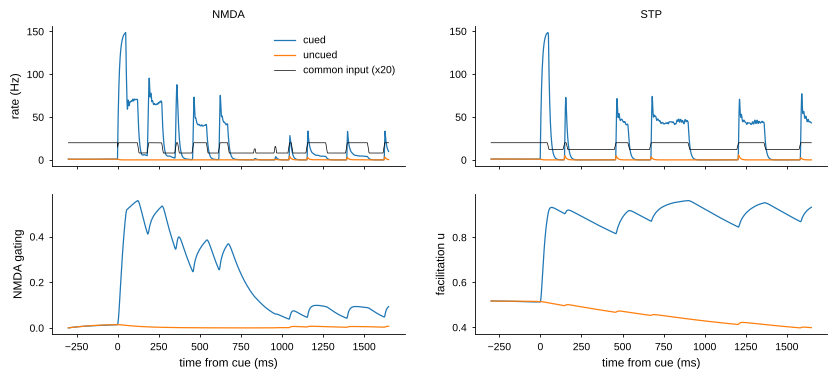

In [3]:
_, ax = plt.subplots(2, 2, figsize=(10, 4), sharex=True)
for j, (name, p) in enumerate((('NMDA', NMDA), ('STP', STP))):
    s = ratemodel.simulate(p, 1, seed=3)
    ax[0, j].plot(s['t'], s['rc'][0], label='cued'); ax[0, j].plot(s['t'], s['ru'][0], label='uncued')
    ax[0, j].plot(s['t'], 20 * s['m'][0], 'k', lw=0.5, label='common input (x20)'); ax[0, j].set_title(name)
    slow = ('sc', 'su') if name == 'NMDA' else ('uc', 'uu')
    ax[1, j].plot(s['t'], s[slow[0]][0]); ax[1, j].plot(s['t'], s[slow[1]][0])
    ax[1, j].set_ylabel(('NMDA gating', 'facilitation u')[j]); ax[1, j].set_xlabel('time from cue (ms)')
ax[0, 0].set_ylabel('rate (Hz)'); ax[0, 0].legend();

In [4]:
ses, hist = readout.load_data()
models = {name: readout.summary(readout.evaluate(p, ses, n_trials=N_TRIALS, seed=SEED), ses, hist)
          for name, p in (('NMDA', NMDA), ('STP', STP))}
print('fit loss, summed over the 7 populations:', {k: round(v.loss.sum()) for k, v in models.items()})
print('memory held:', {k: round(v.memory.iloc[0], 3) for k, v in models.items()})

fit loss, summed over the 7 populations: {'NMDA': 74, 'STP': 79}
memory held: {'NMDA': np.float64(0.984), 'STP': np.float64(1.0)}


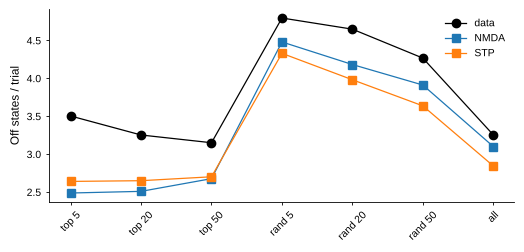

In [5]:
plt.figure(figsize=(6, 2.5))
plt.plot([ses[lab]['off_per_trial'].mean() for lab in models['NMDA'].index], 'k-o', label='data')
for name, m_ in models.items():
    plt.plot(m_.n_off.values, '-s', label=name)
plt.xticks(range(7), models['NMDA'].index, rotation=45); plt.ylabel('Off states / trial'); plt.legend();

## Play: the facilitation time constant
500 trials per value, read out with all units.

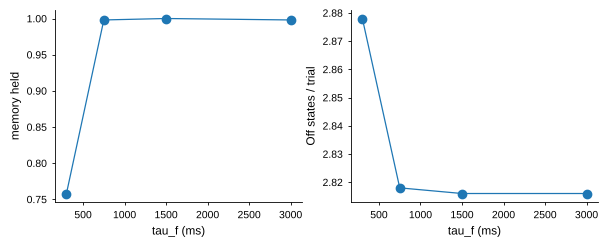

In [6]:
taus_f = (300, 750, 1500, 3000)
play = [readout.evaluate({**STP, 'tau_f': t}, ses, n_trials=500, seed=SEED, sets=('all',)) for t in taus_f]
_, ax = plt.subplots(1, 2, figsize=(7, 2.5))
ax[0].plot(taus_f, [o['mem'] for o in play], 'o-'); ax[0].set_ylabel('memory held')
ax[1].plot(taus_f, [o['sets']['all']['n_off'] for o in play], 'o-'); ax[1].set_ylabel('Off states / trial')
for a in ax:
    a.set_xlabel('tau_f (ms)')

## Figure

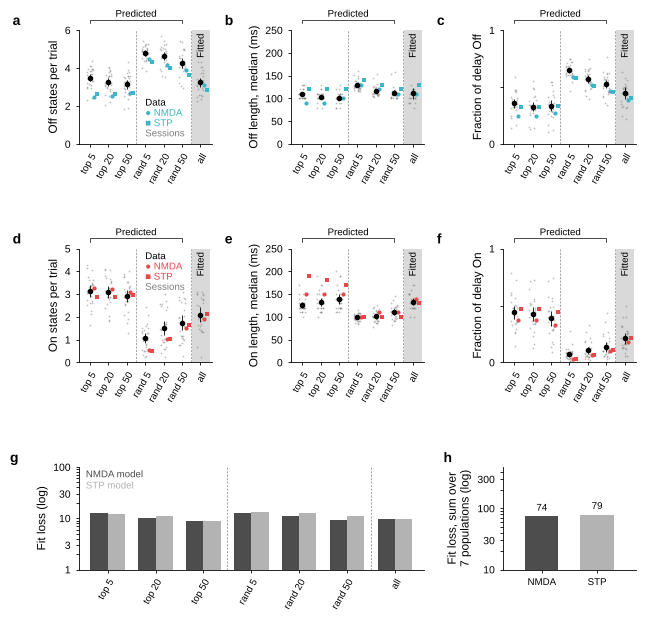

In [7]:
fig = figS3.draw(ses, models)
style.save(fig, '../figures/figS3.png')